# Backtesting on Nasdaq's order feed with exact queue priority

`pip install .` from the repository root, then fetch one stock-day (streams about 3.5 GB, keeps about 7 MB):

```bash
cmake -B build -DCMAKE_BUILD_TYPE=Release && cmake --build build -j
python python/data/fetch_itch.py --days 2019-12-30 --symbols INTC
```

In [1]:
from concurrent.futures import ThreadPoolExecutor
import matplotlib.pyplot as plt, numpy as np, pandas as pd
import lobsim

INTC = "../data/processed/itch_l3/2019-12-30_INTC.l3bin.gz"
NASDAQ = dict(order_size=100, max_position=500, maker_fee_per_unit=0.0, taker_fee_per_unit=0.003,
              session_start="09:35:00", session_end="15:55:00")
lobsim.instrument(INTC)

('INTC', 0.01, 1.0)

## 1. A built-in strategy

Options are the command line's, with underscores. A typo is an error, never silently ignored.

In [2]:
r = lobsim.backtest(INTC, "naive", quote_on_book=True, latency_us=50, **NASDAQ)
pd.Series({k: r[k] for k in ["market_events", "orders_sent", "maker_fills", "maker_volume", "edge", "gross_pnl", "net_pnl", "wall_ms"]}).round(2)

market_events    801251.00
orders_sent        8006.00
maker_fills        3938.00
maker_volume     261788.00
edge                486.46
gross_pnl          -904.77
net_pnl            -905.99
wall_ms             268.37
dtype: float64

In [3]:
try:
    lobsim.backtest(INTC, "naive", order_siez=100)
except RuntimeError as e:
    print(e)

unknown option --order-siez (did you mean --order-size?)


## 2. Where does the money go?

Every fill records the mid at the fill and afterwards. `edge` is the spread captured at the fill; by the 5-second markout the price has given it back, and more.

In [4]:
f = pd.DataFrame(r.fills)
f = f[f.maker == 1]
for h in ["at_fill", "100ms", "1s", "5s", "30s", "60s"]:
    f[h] = f.side * (f["mid_" + h] - f.price) * 100          # cents per share, positive = good for us
hz = ["at_fill", "100ms", "1s", "5s", "30s", "60s"]
f["cause_name"] = [lobsim.FILL_CAUSES[c] for c in f.cause]
tab = f.groupby("cause_name").apply(lambda g: pd.Series({"shares": g.qty.sum(), **{h: np.average(g[h].fillna(0), weights=g.qty) for h in hz}}),
                                    include_groups=False)
tab.round(3)

,shares,at_fill,100ms,1s,5s,30s,60s
cause_name,,,,,,,
book_cross,81994.0,-0.5,-0.404,-0.313,-0.269,-0.361,-0.389
trade_at_price,179695.0,0.5,-0.350,-0.336,-0.272,-0.348,-0.383
trade_through,99.0,0.0,-0.500,-0.500,-1.500,-1.500,-0.500


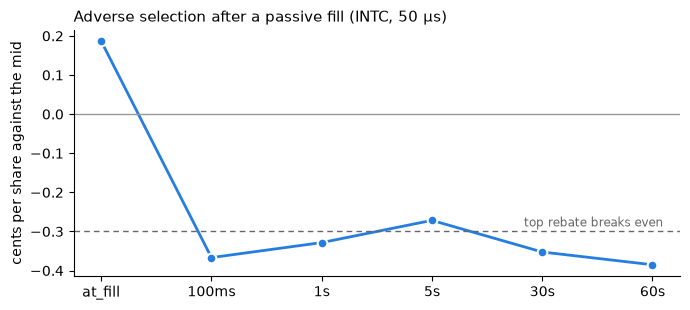

In [5]:
y = [np.average(f[h].fillna(0), weights=f.qty) for h in hz]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(hz, y, color="#257de0", lw=2, marker="o", ms=7, mec="white", mew=1.5)
ax.axhline(0, color="#999", lw=1); ax.axhline(-0.30, color="#666", lw=1, ls=(0, (4, 3)))
ax.text(5.1, -0.295, "top rebate breaks even", ha="right", va="bottom", fontsize=8.5, color="#666")
ax.set_ylabel("cents per share against the mid"); ax.set_title("Adverse selection after a passive fill (INTC, 50 µs)", loc="left", fontsize=11)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout()

## 3. A latency sweep

Built-in strategies release the GIL, so a thread pool runs them in parallel.

In [6]:
lats = [0, 10, 50, 200, 1_000, 10_000]
with ThreadPoolExecutor() as ex:
    runs = list(ex.map(lambda l: lobsim.backtest(INTC, "naive", quote_on_book=True, latency_us=l, equity=False, **NASDAQ), lats))
pd.DataFrame({"latency_us": lats, "shares": [x["maker_volume"] for x in runs],
              "net cents/share before rebate": [x["net_pnl"] / x["maker_volume"] * 100 for x in runs]}).round(3)

,latency_us,shares,net cents/share before rebate
0,0,244398.0,-0.330
1,10,235169.0,-0.353
2,50,261788.0,-0.346
3,200,262697.0,-0.368
4,1000,264727.0,-0.353
5,10000,249232.0,-0.375


## 4. Your own strategy

Subclass `Strategy`. Prices are ticks, sizes are lots, and everything the strategy sees is delayed by the configured latency. This one joins the touch only when the book leans its way and leaves the order alone otherwise.

In [7]:
class LeanJoin(lobsim.Strategy):
    def __init__(self, qty=100, limit=500, lean=0.2):
        super().__init__()
        self.qty, self.limit, self.lean = qty, limit, lean

    def on_book(self, ctx):
        imb = ctx.imbalance()                     # (bid - ask) / (bid + ask) at the touch
        self.side(ctx, "buy", ctx.best_bid[0], imb > self.lean, ctx.position + self.qty <= self.limit)
        self.side(ctx, "sell", ctx.best_ask[0], -imb > self.lean, ctx.position - self.qty >= -self.limit)

    def side(self, ctx, side, touch, join, room):
        live = False
        for i, o in ctx.orders.items():
            if o["side"] != side or o["cancel_sent"]:
                continue
            if o["price"] != touch:
                ctx.cancel(i)                     # the market moved: give up the old price
            else:
                live = True                       # keep our place in the queue
        if join and room and not live:
            ctx.limit(side, touch, self.qty)


opts = {k: v for k, v in NASDAQ.items() if k not in ("order_size", "max_position")}
mine = lobsim.backtest(INTC, LeanJoin(), latency_us=50, **opts)
pd.DataFrame({n: {"shares": x["maker_volume"], "edge c/sh": x["edge"] / x["maker_volume"] * 100,
                  "5 s markout c/sh": x["markout"]["5s"] / x["maker_volume"] * 100,
                  "net c/sh before rebate": x["net_pnl"] / x["maker_volume"] * 100} for n, x in {"naive": r, "LeanJoin": mine}.items()}).round(3)

,naive,LeanJoin
shares,261788.000,181238.000
edge c/sh,0.186,0.271
5 s markout c/sh,-0.269,-0.314
net c/sh before rebate,-0.346,-0.367


One stock and one day: an illustration of the API, not evidence about either strategy. The pre-registered study is in [results/nasdaq](../results/nasdaq).

## 5. The raw order book

In [8]:
rec = lobsim.read_l3(INTC)
print(len(rec), "records;", dict(zip(*np.unique(rec["type"], return_counts=True))))
t = rec["ts"] % 86_400_000_000
book = lobsim.Book()
book.apply(rec[t < 10.5 * 3600 * 1e6])            # the book at 10:30
pd.DataFrame({"bid": book.levels("buy", 5), "ask": book.levels("sell", 5)})

801251 records; {np.uint8(1): np.int64(391756), np.uint8(2): np.int64(383241), np.uint8(3): np.int64(5999), np.uint8(4): np.int64(20255)}


,bid,ask
0,"(5966, 1000)","(5967, 515)"
1,"(5965, 1200)","(5968, 700)"
2,"(5964, 900)","(5969, 468)"
3,"(5963, 2000)","(5970, 765)"
4,"(5962, 1600)","(5971, 800)"
